<a href="https://colab.research.google.com/github/MariaVrett/Logistic-Regression/blob/main/Logistic_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Import Libraries



In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler

#Load Dataset and Info about the Dataset

In [21]:
df = pd.read_csv('diabetes.csv')

print("Variable names:")
print(list(df.columns))
print("\n and short description:")
print("- Pregnancies: Total number of times the patient has been pregnant.")
print("- Glucose: Plasma glucose concentration over 2 hours in an oral glucose tolerance test.")
print("- BloodPressure: Diastolic blood pressure (mm Hg).")
print("- SkinThickness: Triceps skin fold thickness (mm).")
print("- Insulin: 2-Hour serum insulin (mu U/ml).")
print("- BMI: Body mass index (weight in kg / (height in m)^2).")
print("- DiabetesPedigreeFunction: Diabetes pedigree function (quantifies genetic predisposition).")
print("- Age: Age of the patient in years.")
print("- Outcome: Target class variable (0 = Healthy, 1 = Diabetic).\n")
df

Variable names:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']

 and short description:
- Pregnancies: Total number of times the patient has been pregnant.
- Glucose: Plasma glucose concentration over 2 hours in an oral glucose tolerance test.
- BloodPressure: Diastolic blood pressure (mm Hg).
- SkinThickness: Triceps skin fold thickness (mm).
- Insulin: 2-Hour serum insulin (mu U/ml).
- BMI: Body mass index (weight in kg / (height in m)^2).
- DiabetesPedigreeFunction: Diabetes pedigree function (quantifies genetic predisposition).
- Age: Age of the patient in years.
- Outcome: Target class variable (0 = Healthy, 1 = Diabetic).



,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


# df.describe

In [22]:
print(df.describe())


       Pregnancies     Glucose  BloodPressure  SkinThickness     Insulin  \
count   768.000000  768.000000     768.000000     768.000000  768.000000   
mean      3.845052  120.894531      69.105469      20.536458   79.799479   
std       3.369578   31.972618      19.355807      15.952218  115.244002   
min       0.000000    0.000000       0.000000       0.000000    0.000000   
25%       1.000000   99.000000      62.000000       0.000000    0.000000   
50%       3.000000  117.000000      72.000000      23.000000   30.500000   
75%       6.000000  140.250000      80.000000      32.000000  127.250000   
max      17.000000  199.000000     122.000000      99.000000  846.000000   

              BMI  DiabetesPedigreeFunction         Age     Outcome  
count  768.000000                768.000000  768.000000  768.000000  
mean    31.992578                  0.471876   33.240885    0.348958  
std      7.884160                  0.331329   11.760232    0.476951  
min      0.000000                  

# Histograms

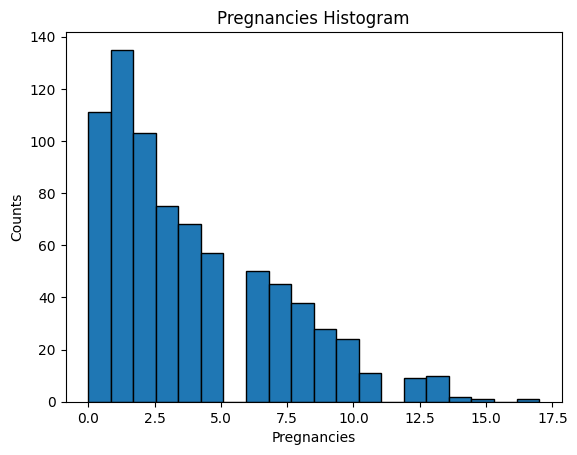

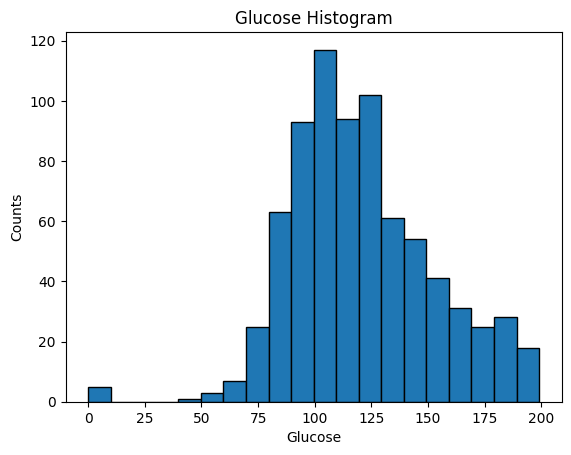

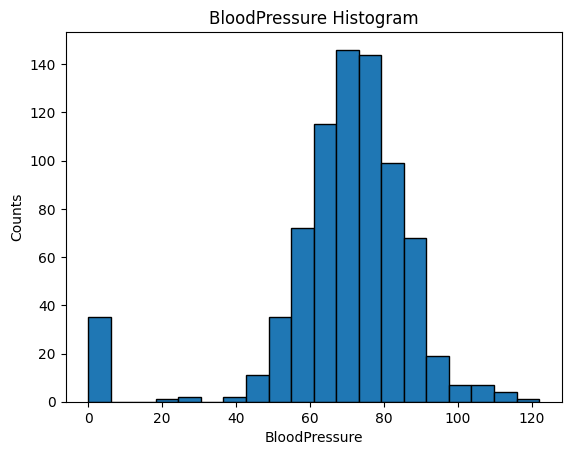

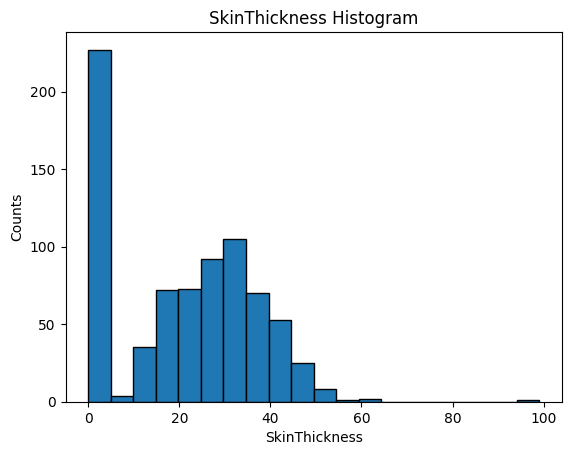

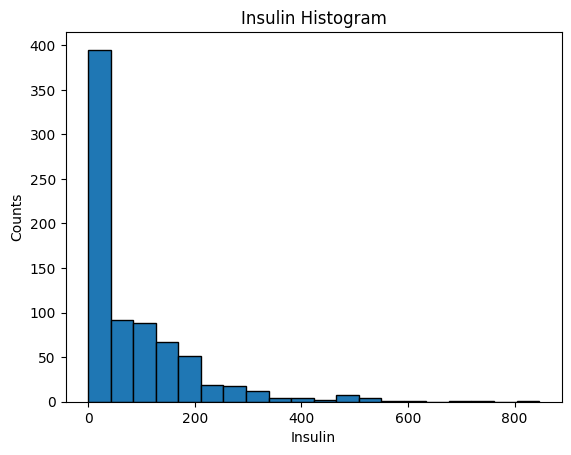

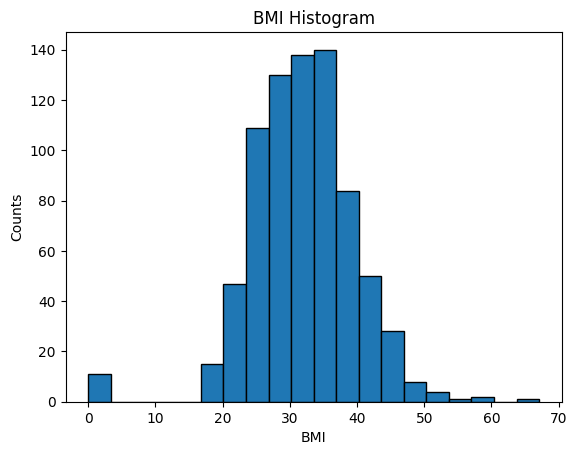

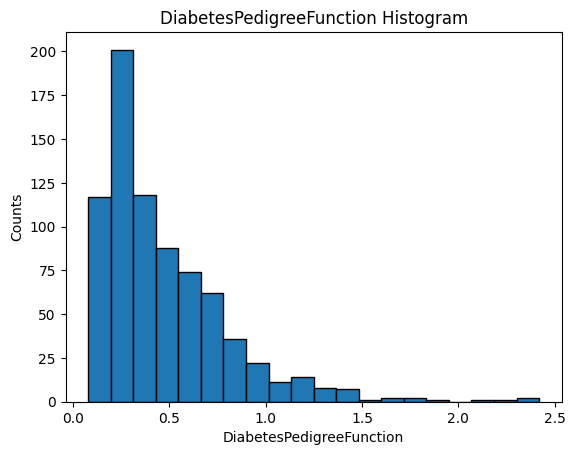

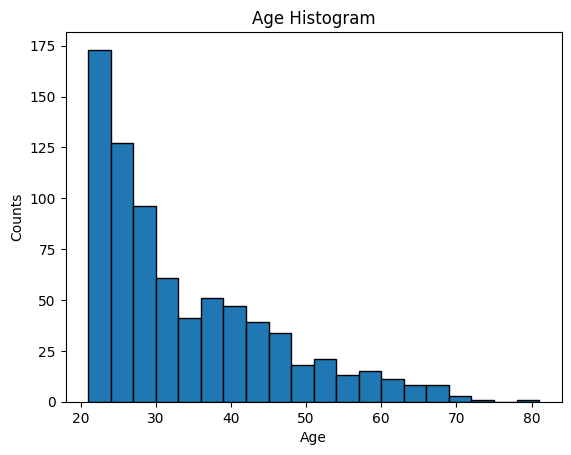

In [23]:
features = df.columns[:-1]
for feature in features:
    df[feature].hist(bins=20, edgecolor='black')
    plt.title(f'{feature} Histogram')
    plt.xlabel(feature)
    plt.ylabel('Counts')
    plt.grid(False)
    plt.show()

#Bar Plot for the Outcome

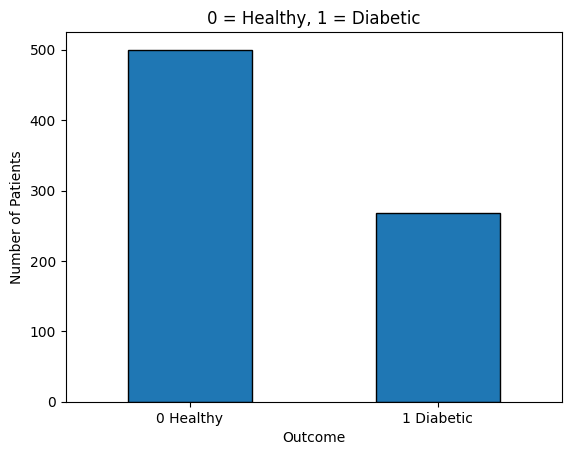

In [24]:
df['Outcome'].value_counts().plot(kind='bar', edgecolor='black')
plt.title('0 = Healthy, 1 = Diabetic')
plt.xlabel('Outcome')
plt.ylabel('Number of Patients')
plt.xticks(ticks=[0, 1], labels=['0 Healthy', '1 Diabetic'], rotation=0)
plt.grid(False)
plt.show()

# Convert DataFrame to Numpy arrays and Split Dataset to Train-Test

In [25]:
input_df = df.drop(columns=['Outcome'])
targets_df = df['Outcome']

x = input_df.to_numpy()
y = targets_df.to_numpy()
x.shape, y.shape
seed=0
test_size = 0.30

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=test_size, random_state=seed)
print(x_train.shape, y_train.shape, x_test.shape, y_test.shape)

(537, 8) (537,) (231, 8) (231,)


# Create a Logistic Regression Model

In [26]:
model = LogisticRegression(max_iter=5000, random_state=seed)

# Train model on training set

In [27]:
model.fit(x_train, y_train)

LogisticRegression(max_iter=5000, random_state=0)

# Accuracy of Train and Test Set

In [28]:
y_pred_train = model.predict(x_train)
y_pred_test = model.predict(x_test)

train_accuracy = accuracy_score(y_train, y_pred_train) * 100
test_accuracy = accuracy_score(y_test, y_pred_test) * 100

print(f'Train Accuracy: {train_accuracy:.2f}%')
print(f'Test Accuracy:  {test_accuracy:.2f}%')
print("The accuracy on the test set is slightly higher than the train set. This indicates that the model does not suffer from overfitting.")

Train Accuracy: 76.54%
Test Accuracy:  77.92%
The accuracy on the test set is slightly higher than the train set. This indicates that the model does not suffer from overfitting.


# Data Normalization

In [29]:
scaler = StandardScaler()
scaler.fit(x_train)

x_train_scaled = scaler.transform(x_train)
x_test_scaled = scaler.transform(x_test)

# Glucose and Diabetes Correlation

Mean Glucose levels by Outcome:
Outcome
0    109.980000
1    141.257463
Name: Glucose, dtype: float64

Pearson correlation coefficient between Glucose and Outcome: 0.467


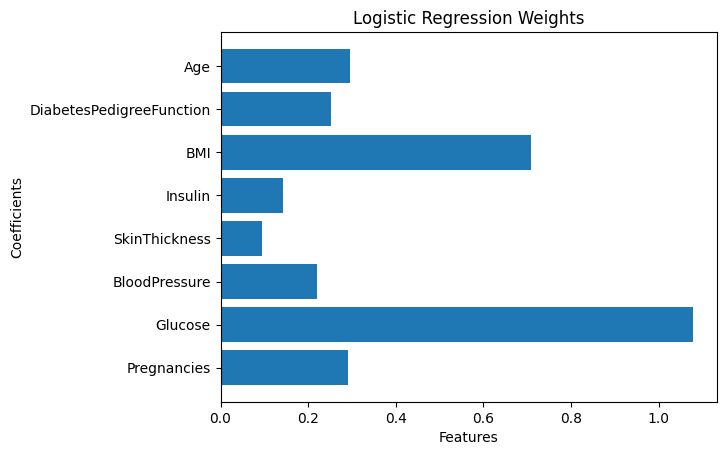

Patients diagnosed with diabetes have a significantly higher mean glucose level compared to healthy patients
Glucose has the strongest positive correlation with the target variable.


In [30]:
model.fit(x_train_scaled, y_train)
mean_glucose = df.groupby('Outcome')['Glucose'].mean()
corr_glucose = df['Glucose'].corr(df['Outcome'])

print("Mean Glucose levels by Outcome:")
print(mean_glucose)
print(f"\nPearson correlation coefficient between Glucose and Outcome: {corr_glucose:.3f}")

coeffs = model.coef_[0]
importance_weights = np.abs(coeffs)
plt.barh(input_df.columns, importance_weights)
plt.title('Logistic Regression Weights')
plt.xlabel('Features')
plt.ylabel('Coefficients')
plt.show()

print("Patients diagnosed with diabetes have a significantly higher mean glucose level compared to healthy patients")
print("Glucose has the strongest positive correlation with the target variable.")

# DataFrame for the test set to include Age and Predictions

In [31]:
test_df = pd.DataFrame(x_test, columns=features)
test_df['y_true'] = y_test
test_df['y_pred'] = y_pred_test

# Define age bins: 0-25, 25-50, >50

In [32]:
bins = [0, 25, 50, 120]
labels = ['0-25', '25-50', '>50']
test_df['Age_Group'] = pd.cut(test_df['Age'], bins=bins, labels=labels, right=True)

# Calculate accuracy for each group

In [33]:
group_acc = test_df.groupby('Age_Group', observed=False).apply(lambda g: accuracy_score(g['y_true'], g['y_pred']), include_groups=False)
print('Accuracy by Age Group in Test Set:')
print(group_acc * 100)

Accuracy by Age Group in Test Set:
Age_Group
0-25     85.555556
25-50    70.000000
>50      90.476190
dtype: float64


# Plot the bar chart for Accuracy by Age Group

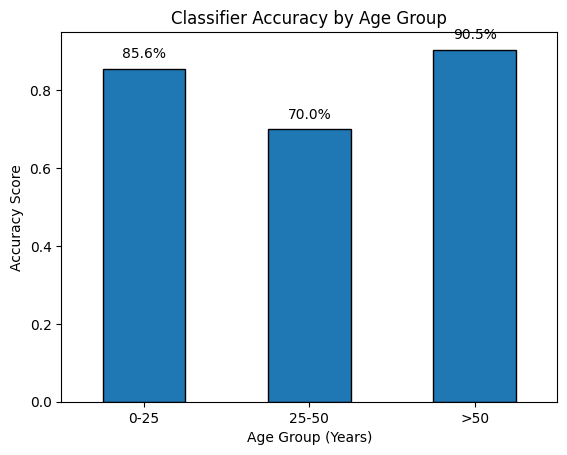

In [34]:
plt.figure()
ax = group_acc.plot(kind='bar', edgecolor='black')
plt.title('Classifier Accuracy by Age Group')
plt.xlabel('Age Group (Years)')
plt.ylabel('Accuracy Score')
plt.ylim()
plt.grid(False)

for idx, value in enumerate(group_acc):
  ax.text(
      idx,
      value + 0.02,
      f'{value*100:.1f}%',
      ha='center',
      va='bottom',
  )

plt.xticks(rotation=0)
plt.show()

# Type of Error

In [35]:
print("A false negative is worse than a false positive because a patient will be sent home thinking they are healthy. They will be missing out on treatment and medication and this will lead to their condition to be worsening ")

A false negative is worse than a false positive because a patient will be sent home thinking they are healthy. They will be missing out on treatment and medication and this will lead to their condition to be worsening 
